<a href="https://colab.research.google.com/github/martidanims-netizen/TAREA-2-FUNDAMENTO-DE-PROCESAMIENTO-DE-IM-GENES/blob/main/TAREA_2_pregunta_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA 2: PRIMERA PREGUNTA**
Inicialmente defino las funciones que son útiles para ambas implementaciones.

In [29]:
#LIBRERIAS
import numpy as np
import matplotlib.pyplot as plt
import skimage as ski
import scipy
import scipy.signal


In [30]:
#RUIDO
lam=40
def agregar_ruido_poisson(imagen, lam):
    imagen_ruidosa = np.random.poisson(imagen * lam) / lam
    imagen_ruidosa = np.clip(imagen_ruidosa, 0, 1)
    return imagen_ruidosa

img=(agregar_ruido_poisson(imagen,lam))

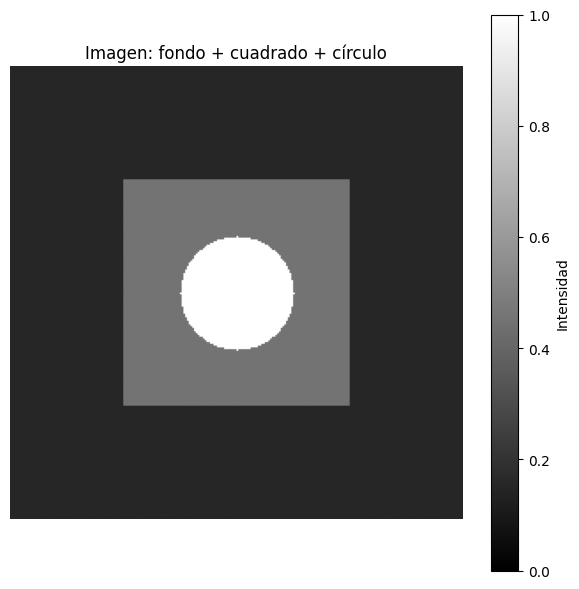

In [31]:
#FIGURA

h, w = 256, 256
y_i, x_i = np.ogrid[:h, :w] #indices #crea las rejillas
centro_y, centro_x = h // 2, w // 2

#creo la base para la imagen
imagen_vacia=np.full((h,w),0.15,dtype=np.float32)

#cuadrado central
imagen_vacia[centro_y-64:centro_y+64,centro_x-64:centro_x+64]=0.45

#circulo central
radio=32
circunferencia=(y_i-centro_y)**2+(x_i-centro_x)**2<=radio**2
imagen_vacia[circunferencia]=1

#Para simplificar
imagen=imagen_vacia

plt.figure(figsize=(6, 6))
plt.imshow(imagen, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen: fondo + cuadrado + círculo')
plt.colorbar(label='Intensidad')
plt.axis('off')
plt.tight_layout()
plt.show()


Para la primera implementación se solicita Implementar la construcción de un kernel Gaussiano isotrópico a partir de σ, normalizando los coeficientes.

In [32]:
#KERNEL GAUSSIANO PARA PRIMERA IMPLEMENTACIÓN

def kernelg(sigma):
    radio=int(np.ceil(3*sigma)) #npceil para asegurar q de tener decimal se aproxime hacia arriba
    Xk=np.arange(-radio,+radio+1) #arenge de 1 a 1 pixel
    Yk=np.arange(-radio,+radio+1)

    X,Y=np.meshgrid(Xk,Yk)

    kernel_gauss = np.exp(-(X**2 + Y**2)/(2*sigma**2)) #no se calcula la parte entera porque es innecesaria, se elimina luego al normalizar
    kernel_normalizado = kernel_gauss / (np.sum(kernel_gauss))

    return kernel_normalizado


   Explore un rango suficientemente amplio y denso de valores de $\sigma$ para identificar el mínimo de RMSE. Incluya también el caso sin filtrado como referencia.

   Para cada σ, calcule el RMSE por separado en las tres regiones y el
RMSE global. Grafique las curvas RMSE(σ) de las tres regiones en una
misma figura y marque los mínimos encontrados. Muestre también el
mínimo global.

<>:57: SyntaxWarning: invalid escape sequence '\s'
<>:58: SyntaxWarning: invalid escape sequence '\s'
<>:57: SyntaxWarning: invalid escape sequence '\s'
<>:58: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1304/2235505862.py:57: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Error RMSE por regiones para distintos $\sigma$')
/tmp/ipykernel_1304/2235505862.py:58: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Valor de $\sigma$')


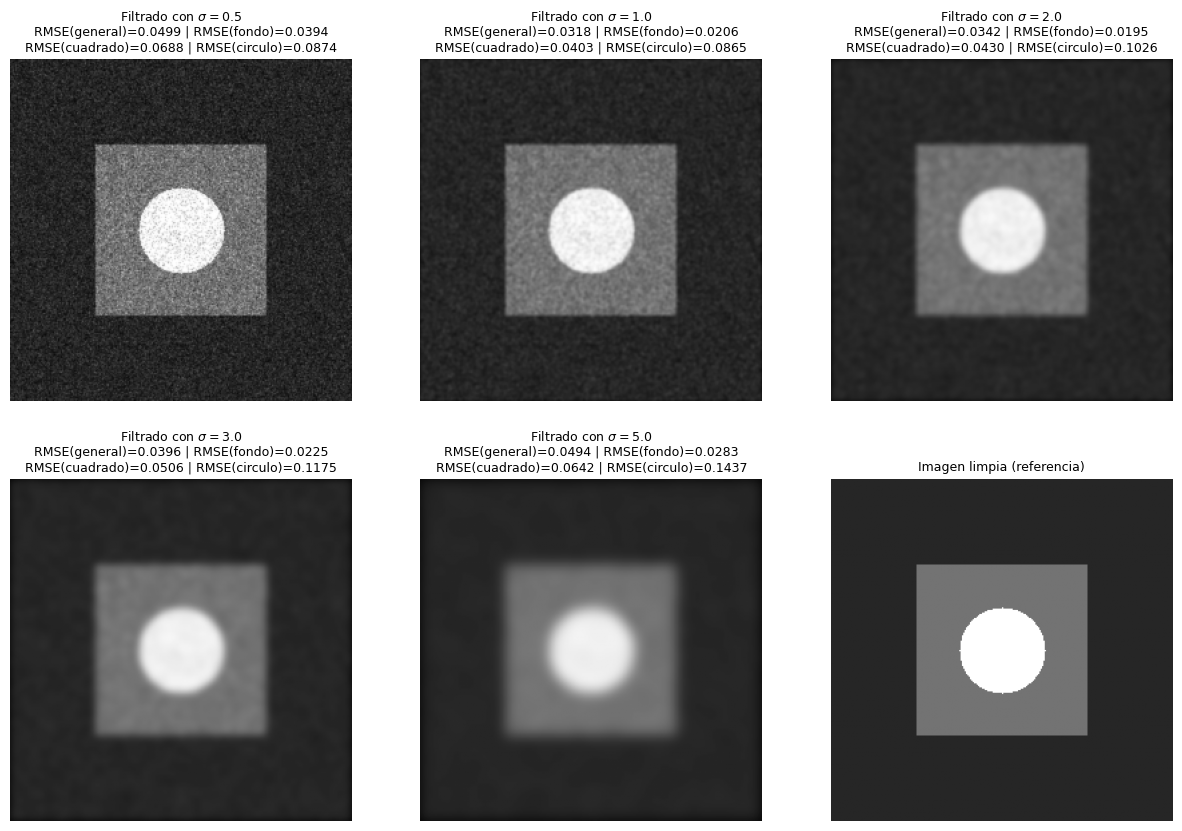

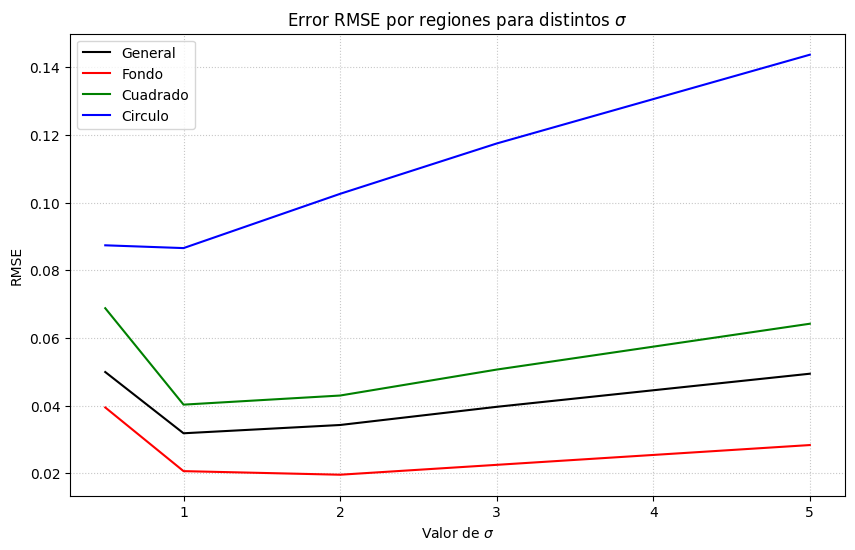

In [35]:
arreglo_sigma=[0.5, 1.0, 2.0, 3.0, 5.0]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes=axes.ravel()

def calculo_rmse(imagen,imagencondenoising,mascara=None):
    if mascara is None:
        rmse=np.sqrt(np.mean((imagen-imagencondenoising)**2))
    else:
        rmse=np.sqrt(np.mean((imagen[mascara]-imagencondenoising[mascara])**2))
    return rmse

rmse_general=[]
rmse_fondo=[]
rmse_cuadrado=[]
rmse_circulo=[]

circulo=imagen==1
cuadrado=imagen==0.45
fondo=imagen==0.15

for ind, i in enumerate(arreglo_sigma):
    matrizker=kernelg(i)
    imagencondenoising=scipy.signal.convolve2d(img,matrizker,mode='same')

    rmse_general.append(calculo_rmse(imagen,imagencondenoising))
    rmse_fondo.append(calculo_rmse(imagen,imagencondenoising,fondo))
    rmse_cuadrado.append(calculo_rmse(imagen,imagencondenoising,cuadrado))
    rmse_circulo.append(calculo_rmse(imagen,imagencondenoising,circulo))

    axes[ind].imshow(imagencondenoising, cmap='gray', vmin=0, vmax=1)
    axes[ind].set_title(rf'Filtrado con $\sigma = {i}$' + '\n' + f'RMSE(general)={rmse_general[ind]:.4f} | RMSE(fondo)={rmse_fondo[ind]:.4f}\n'+ f'RMSE(cuadrado)={rmse_cuadrado[ind]:.4f} | RMSE(circulo)={rmse_circulo[ind]:.4f}',fontsize=9)
    axes[ind].axis('off')

axes[len(arreglo_sigma)].imshow(imagen, cmap='gray', vmin=0, vmax=1)
axes[len(arreglo_sigma)].set_title('Imagen limpia (referencia)', fontsize=9)
axes[len(arreglo_sigma)].axis('off')

#ordenar en array
rmse_general=np.array(rmse_general)
rmse_fondo=np.array(rmse_fondo)
rmse_cuadrado=np.array(rmse_cuadrado)
rmse_circulo=np.array(rmse_circulo)

#ahora busco los valores mínimos
min_general=np.argmin(rmse_general)
min_fondo=np.argmin(rmse_fondo)
min_cuadrado=np.argmin(rmse_cuadrado)
min_circulo=np.argmin(rmse_circulo)

plt.figure(figsize=(10, 6))

plt.plot(arreglo_sigma,rmse_general,label='General',color='black')
plt.plot(arreglo_sigma,rmse_fondo,label='Fondo',color='red')
plt.plot(arreglo_sigma,rmse_cuadrado,label='Cuadrado',color='green')
plt.plot(arreglo_sigma,rmse_circulo,label='Circulo',color='blue')

#para marcar minimos
plt.plot(arreglo_sigma[min_general],rmse_general[min_general],color='black',markersize=8)
plt.plot(arreglo_sigma[min_fondo],rmse_fondo[min_fondo],color='red',markersize=8)
plt.plot(arreglo_sigma[min_cuadrado],rmse_cuadrado[min_cuadrado],color='green',markersize=8)
plt.plot(arreglo_sigma[min_circulo],rmse_circulo[min_circulo],color='blue',markersize=8)

plt.title('Error RMSE por regiones para distintos $\sigma$')
plt.xlabel('Valor de $\sigma$')
plt.ylabel('RMSE')
plt.legend()
plt.grid(True,linestyle=':',alpha=0.7)

plt.show()

**Segunda implementación**:
Después del estudio global descrito más abajo, implemente una versión
espacialmente adaptativa en la cual σ pueda variar con la posición. El
mapeo desde una estimación local de intensidad μ(x, y) hacia σ(x, y)
debe ser diseñado por usted a partir de los resultados experimentales.

<>:56: SyntaxWarning: invalid escape sequence '\s'
<>:61: SyntaxWarning: invalid escape sequence '\s'
<>:56: SyntaxWarning: invalid escape sequence '\s'
<>:61: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1304/233285738.py:56: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Mapa de $\sigma$')
/tmp/ipykernel_1304/233285738.py:61: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Mapa de $\sigma$')


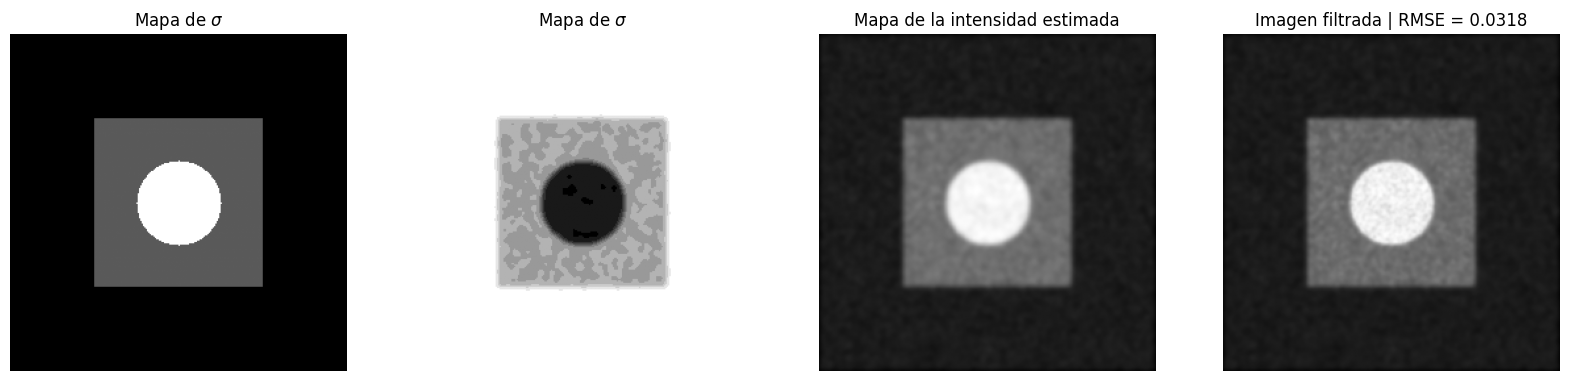

In [36]:
#KERNEL GAUSSIANO ADAPTATIVO
def kernelg(sigma):
    radio=int(np.ceil(3*sigma)) #npceil para asegurar q de tener decimal se aproxime hacia arriba
    Xk=np.arange(-radio,+radio+1) #arenge de 1 a 1 pixel
    Yk=np.arange(-radio,+radio+1)

    X,Y=np.meshgrid(Xk,Yk)

    kernel_gauss = np.exp(-(X**2 + Y**2)/(2*sigma**2)) #no se calcula la parte entera porque es innecesaria, se elimina luego al normalizar
    kernel_normalizado = kernel_gauss / (np.sum(kernel_gauss))

    return kernel_normalizado

#usando el mismo kernel gaussiano podría calcular el promedio de los pixeles para medir la intensidad, y a esto relacionarlo con un valor sigma

#intensidad baja
mu=0.15
sigma=2
#intensidad alta
mu=1
sigma=1

kernel_interp=kernelg(2)
imagenmapa=scipy.signal.convolve2d(img,kernel_interp,mode='same')
sigma_variable=(-1.176*imagenmapa)+2.176
sigma_map = np.clip(sigma_variable, 1.0, 2.0)

#aproximación
sigma_map=np.round(sigma_map,1)
sigma_puntual=np.unique(sigma_map)

#imagen nueva
imagen_con_sigma_adaptado=np.zeros_like(img)

#loop para recorrer mapa:
for s in sigma_puntual:
    mascara_s = (sigma_map==s) #buscar donde sigma vale s y obtener mascara
    k=kernelg(s) #obtener el kernel para ese sigma
    img_filtrada=scipy.signal.convolve2d(img,k,mode='same') #obtener imagen
    imagen_con_sigma_adaptado[mascara_s]=img_filtrada[mascara_s]

def calculo_rmse(imagen,imagencondenoising,mascara=None):
    if mascara is None:
        rmse=np.sqrt(np.mean((imagen-imagencondenoising)**2))
    else:
        rmse=np.sqrt(np.mean((imagen[mascara]-imagencondenoising[mascara])**2))
    return rmse

rmse_adaptado=calculo_rmse(imagen,imagen_con_sigma_adaptado,mascara=None)

#visualizar
plt.figure(figsize=(20, 5))

plt.subplot(1,4,1)
plt.imshow(imagen, cmap='gray')
plt.title('Mapa de $\sigma$')
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(sigma_map, cmap='gray')
plt.title('Mapa de $\sigma$')
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(imagenmapa, cmap='gray')
plt.title('Mapa de la intensidad estimada')
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(imagen_con_sigma_adaptado, cmap='gray')
plt.title(f'Imagen filtrada | RMSE = {rmse_adaptado:.4f}')
plt.axis('off')

plt.show()
